# Final Project
## Team member: Hung Jui Chao, Haojun Gong, Samuel Hsu, Shih-En Lee
* Q1: How do traffic patterns affect trip efficiency? Which service provide the best efficiency?
* Q2: Which routes generate the highest revenue efficiency?
* Q3: How do fares and driver earnings differ across services?

In [2]:
%pip install plotly

     |████████████████████████████████| 9.7 MB 445 kB/s eta 0:00:01
     |████████████████████████████████| 359 kB 8.2 MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import statsmodels.api as sm

In [6]:
yellow = pd.read_parquet("yellow_tripdata_2026-05.parquet")
uberlyft = pd.read_parquet("fhvhv_tripdata_2026-05.parquet")

In [7]:
yellow.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-05-01 00:04:59,2026-05-01 00:32:48,1.0,7.51,1.0,N,138,37,2,35.9,6.00,0.5,0.00,0.0,1.0,45.40,0.0,2.0,0.00
1,2,2026-05-01 00:37:05,2026-05-01 00:59:47,1.0,6.14,1.0,N,138,237,1,27.5,6.00,0.5,9.56,0.0,1.0,49.81,2.5,2.0,0.75
2,1,2026-05-01 00:34:05,2026-05-01 00:54:02,1.0,2.40,1.0,N,249,232,1,19.1,4.25,0.5,3.73,0.0,1.0,28.58,2.5,0.0,0.75
3,1,2026-05-01 00:55:07,2026-05-01 01:02:43,0.0,1.20,1.0,N,232,114,1,9.3,4.25,0.5,3.00,0.0,1.0,18.05,2.5,0.0,0.75
4,7,2026-05-01 00:44:13,2026-05-01 00:44:13,2.0,0.86,1.0,N,140,237,1,7.2,0.00,0.5,2.44,0.0,1.0,14.64,2.5,0.0,0.00


In [8]:
uberlyft.head()

,hvfhs_license_num,dispatching_base_num,originating_base_num,request_datetime,on_scene_datetime,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,trip_miles,...,congestion_surcharge,airport_fee,tips,driver_pay,shared_request_flag,shared_match_flag,access_a_ride_flag,wav_request_flag,wav_match_flag,cbd_congestion_fee
0,HV0003,B03404,B03404,2026-05-01 00:15:29,2026-05-01 00:18:00,2026-05-01 00:18:20,2026-05-01 00:35:57,164,263,3.370,...,2.75,0.0,0.0,23.52,N,N,N,N,N,1.5
1,HV0003,B03404,B03404,2026-05-01 00:53:01,2026-05-01 00:54:40,2026-05-01 00:57:24,2026-05-01 01:13:46,161,137,2.770,...,2.75,0.0,0.0,21.53,N,N,N,N,N,1.5
2,HV0005,B03406,None,2026-05-01 00:42:11,2026-05-01 00:44:12,2026-05-01 00:44:16,2026-05-01 01:00:33,48,265,4.868,...,0.00,0.0,4.1,19.30,N,N,N,N,N,1.5
3,HV0005,B03406,B03406,2026-05-01 00:34:36,2026-05-01 00:27:32,2026-05-01 00:27:39,2026-05-01 00:35:37,219,203,1.422,...,0.00,0.0,0.0,7.71,N,N,N,Y,Y,0.0
4,HV0005,B03406,None,2026-05-01 00:06:52,2026-05-01 00:09:38,2026-05-01 00:10:38,2026-05-01 00:17:20,41,42,1.535,...,0.00,0.0,0.0,6.53,N,N,N,N,N,0.0


### Import Zone Information

In [9]:
zone = pd.read_excel("Zone Info.xlsx")
zone.head()

,LocationID,Borough,Zone,service_zone,long,lat
0,1,EWR,Newark Airport,EWR,-74.176786,40.689516
1,2,Queens,Jamaica Bay,Boro Zone,-73.826126,40.625724
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone,-73.849479,40.865888
3,4,Manhattan,Alphabet City,Yellow Zone,-73.977023,40.724152
4,5,Staten Island,Arden Heights,Boro Zone,-74.189930,40.550340


### Add into yellow cab and uber/lyft dataset

In [10]:
# Make sure Location IDs have the same data type
zone["LocationID"] = pd.to_numeric(zone["LocationID"], errors="coerce")
yellow["PULocationID"] = pd.to_numeric(yellow["PULocationID"], errors="coerce")
yellow["DOLocationID"] = pd.to_numeric(yellow["DOLocationID"], errors="coerce")

# Add Pickup Zone
yellow = yellow.merge(
    zone[["LocationID", "Zone"]].rename(
        columns={"Zone": "Pickup_Zone"}
    ),
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
).drop(columns="LocationID")

# Add Dropoff Zone
yellow = yellow.merge(
    zone[["LocationID", "Zone"]].rename(
        columns={"Zone": "Dropoff_Zone"}
    ),
    left_on="DOLocationID",
    right_on="LocationID",
    how="left"
).drop(columns="LocationID")

In [12]:
yellow.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,Pickup_Zone,Dropoff_Zone
0,2,2026-05-01 00:04:59,2026-05-01 00:32:48,1.0,7.51,1.0,N,138,37,2,...,0.5,0.00,0.0,1.0,45.40,0.0,2.0,0.00,LaGuardia Airport,Bushwick South
1,2,2026-05-01 00:37:05,2026-05-01 00:59:47,1.0,6.14,1.0,N,138,237,1,...,0.5,9.56,0.0,1.0,49.81,2.5,2.0,0.75,LaGuardia Airport,Upper East Side South
2,1,2026-05-01 00:34:05,2026-05-01 00:54:02,1.0,2.40,1.0,N,249,232,1,...,0.5,3.73,0.0,1.0,28.58,2.5,0.0,0.75,West Village,Two Bridges/Seward Park
3,1,2026-05-01 00:55:07,2026-05-01 01:02:43,0.0,1.20,1.0,N,232,114,1,...,0.5,3.00,0.0,1.0,18.05,2.5,0.0,0.75,Two Bridges/Seward Park,Greenwich Village South
4,7,2026-05-01 00:44:13,2026-05-01 00:44:13,2.0,0.86,1.0,N,140,237,1,...,0.5,2.44,0.0,1.0,14.64,2.5,0.0,0.00,Lenox Hill East,Upper East Side South


In [13]:
# Add Pickup Zone
uberlyft = uberlyft.merge(
    zone[["LocationID", "Zone"]].rename(
        columns={"Zone": "Pickup_Zone"}
    ),
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
).drop(columns="LocationID")

# Add Dropoff Zone
uberlyft = uberlyft.merge(
    zone[["LocationID", "Zone"]].rename(
        columns={"Zone": "Dropoff_Zone"}
    ),
    left_on="DOLocationID",
    right_on="LocationID",
    how="left"
).drop(columns="LocationID")

In [14]:
uberlyft.head()

,hvfhs_license_num,dispatching_base_num,originating_base_num,request_datetime,on_scene_datetime,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,trip_miles,...,tips,driver_pay,shared_request_flag,shared_match_flag,access_a_ride_flag,wav_request_flag,wav_match_flag,cbd_congestion_fee,Pickup_Zone,Dropoff_Zone
0,HV0003,B03404,B03404,2026-05-01 00:15:29,2026-05-01 00:18:00,2026-05-01 00:18:20,2026-05-01 00:35:57,164,263,3.370,...,0.0,23.52,N,N,N,N,N,1.5,Midtown South,Yorkville West
1,HV0003,B03404,B03404,2026-05-01 00:53:01,2026-05-01 00:54:40,2026-05-01 00:57:24,2026-05-01 01:13:46,161,137,2.770,...,0.0,21.53,N,N,N,N,N,1.5,Midtown Center,Kips Bay
2,HV0005,B03406,None,2026-05-01 00:42:11,2026-05-01 00:44:12,2026-05-01 00:44:16,2026-05-01 01:00:33,48,265,4.868,...,4.1,19.30,N,N,N,N,N,1.5,Clinton East,NaN
3,HV0005,B03406,B03406,2026-05-01 00:34:36,2026-05-01 00:27:32,2026-05-01 00:27:39,2026-05-01 00:35:37,219,203,1.422,...,0.0,7.71,N,N,N,Y,Y,0.0,Springfield Gardens South,Rosedale
4,HV0005,B03406,None,2026-05-01 00:06:52,2026-05-01 00:09:38,2026-05-01 00:10:38,2026-05-01 00:17:20,41,42,1.535,...,0.0,6.53,N,N,N,N,N,0.0,Central Harlem,Central Harlem North


## Q1: How do traffic patterns affect trip efficiency?

### Step1: Data Preparation

In [15]:
# Q1 - Step 1: Data Preparation

# Yellow Taxi
yellow["pickup_datetime"] = pd.to_datetime(
    yellow["tpep_pickup_datetime"]
)

yellow["dropoff_datetime"] = pd.to_datetime(
    yellow["tpep_dropoff_datetime"]
)

# Uber / Lyft
uberlyft["pickup_datetime"] = pd.to_datetime(
    uberlyft["pickup_datetime"]
)

uberlyft["dropoff_datetime"] = pd.to_datetime(
    uberlyft["dropoff_datetime"]
)

# Calculate trip duration and speed
for df in [yellow, uberlyft]:

    df["Trip_Duration"] = (
        df["dropoff_datetime"] - df["pickup_datetime"]
    ).dt.total_seconds() / 60

    df["Average_Speed"] = (
        df["trip_miles"] / (df["Trip_Duration"] / 60)
        if "trip_miles" in df.columns
        else df["trip_distance"] / (df["Trip_Duration"] / 60)
    )

    df["Hour"] = df["pickup_datetime"].dt.hour

    df["Weekday"] = df["pickup_datetime"].dt.day_name()

    df["Date"] = df["pickup_datetime"].dt.date

In [16]:
print("Yellow Taxi:")
display(yellow[[
    "Trip_Duration", "Average_Speed",
    "Hour", "Weekday", "Date"
]].head())

print("Uber / Lyft:")
display(uberlyft[[
    "Trip_Duration", "Average_Speed",
    "Hour", "Weekday", "Date"
]].head())

Yellow Taxi:


,Trip_Duration,Average_Speed,Hour,Weekday,Date
0,27.816667,16.198922,0,Friday,2026-05-01
1,22.700000,16.229075,0,Friday,2026-05-01
2,19.950000,7.218045,0,Friday,2026-05-01
3,7.600000,9.473684,0,Friday,2026-05-01
4,0.000000,inf,0,Friday,2026-05-01


Uber / Lyft:


,Trip_Duration,Average_Speed,Hour,Weekday,Date
0,17.616667,11.477767,0,Friday,2026-05-01
1,16.366667,10.154786,0,Friday,2026-05-01
2,16.283333,17.937359,0,Friday,2026-05-01
3,7.966667,10.709623,0,Friday,2026-05-01
4,6.700000,13.746269,0,Friday,2026-05-01


### Check invalid Data: 
* Trip Duration <= 0
* Trip Distance <= 0
* Average Speed <= 0MPH or Average Speed > 80MPH
* Trip Duration is negative

In [17]:
for name, df in [("Yellow Taxi", yellow), ("Uber/Lyft", uberlyft)]:

    print(f"\n{name}")

    print("Total Trips:", len(df))

    print("Invalid Duration:",
          (df["Trip_Duration"] <= 0).sum())

    print("Invalid Speed:",
          ((df["Average_Speed"] <= 0) |
           (df["Average_Speed"] > 80)).sum())

    print("Missing Speed:",
          df["Average_Speed"].isna().sum())


Yellow Taxi
Total Trips: 4090836
Invalid Duration: 52063
Invalid Speed: 163840
Missing Speed: 1137

Uber/Lyft
Total Trips: 22125744
Invalid Duration: 0
Invalid Speed: 2963
Missing Speed: 0


### Step4: Cleaning Data
#### Keep reasonable data:
* Trip Duration 1-180min
* Average Speed > 0 and <= 80MPH
* Trip Distance > 0
* PickUP Date in May

In [18]:
# Q1 - Step 4: Data Cleaning

yellow_q1 = yellow[
    (yellow["Trip_Duration"].between(1, 180)) & 
    (yellow["Average_Speed"] > 0) &
    (yellow["Average_Speed"] <= 80) &
    (yellow["trip_distance"] > 0) &
    (yellow["pickup_datetime"].dt.year == 2026) &
    (yellow["pickup_datetime"].dt.month == 5)
].copy()

uberlyft_q1 = uberlyft[
    (uberlyft["Trip_Duration"].between(1, 180)) &
    (uberlyft["Average_Speed"] > 0) &
    (uberlyft["Average_Speed"] <= 80) &
    (uberlyft["trip_miles"] > 0) &
    (uberlyft["pickup_datetime"].dt.year == 2026) &
    (uberlyft["pickup_datetime"].dt.month == 5)
].copy()

print("Yellow Taxi:")
print("Original:", len(yellow))
print("Cleaned:", len(yellow_q1))

print("\nUber/Lyft:")
print("Original:", len(uberlyft))
print("Cleaned:", len(uberlyft_q1))

Yellow Taxi:
Original: 4090836
Cleaned: 3912000

Uber/Lyft:
Original: 22125744
Cleaned: 22119701


### Step5: Line Chart

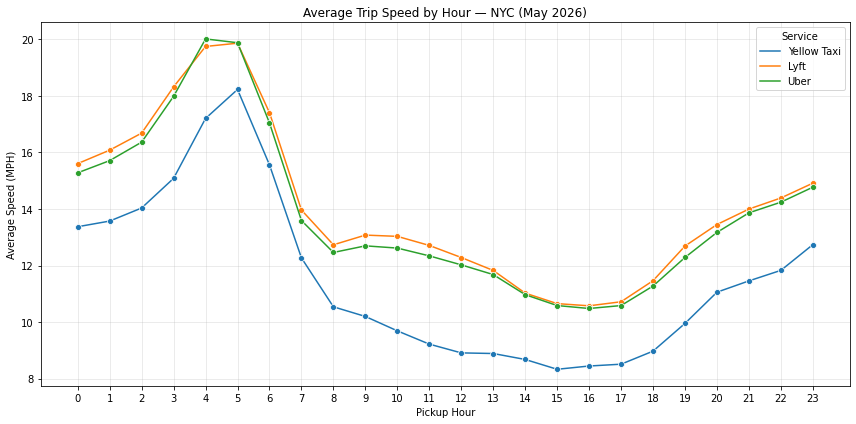

In [19]:
# Identify Uber and Lyft
uberlyft_q1["Service"] = uberlyft_q1["hvfhs_license_num"].map({
    "HV0003": "Uber",
    "HV0005": "Lyft"
})

yellow_q1["Service"] = "Yellow Taxi"

# Calculate average speed by hour
yellow_hourly = (
    yellow_q1.groupby(["Service", "Hour"])["Average_Speed"]
    .mean()
    .reset_index()
)

uberlyft_hourly = (
    uberlyft_q1.groupby(["Service", "Hour"])["Average_Speed"]
    .mean()
    .reset_index()
)

# Combine results
hourly_speed = pd.concat(
    [yellow_hourly, uberlyft_hourly],
    ignore_index=True
)

# Plot
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_speed,
    x="Hour",
    y="Average_Speed",
    hue="Service",
    marker="o"
)

plt.title("Average Trip Speed by Hour — NYC (May 2026)")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Speed (MPH)")
plt.xticks(range(24))
plt.legend(title="Service")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Step6: Traffic Heatmap
* Total traffic Heatmap
* Which Service provide the best service

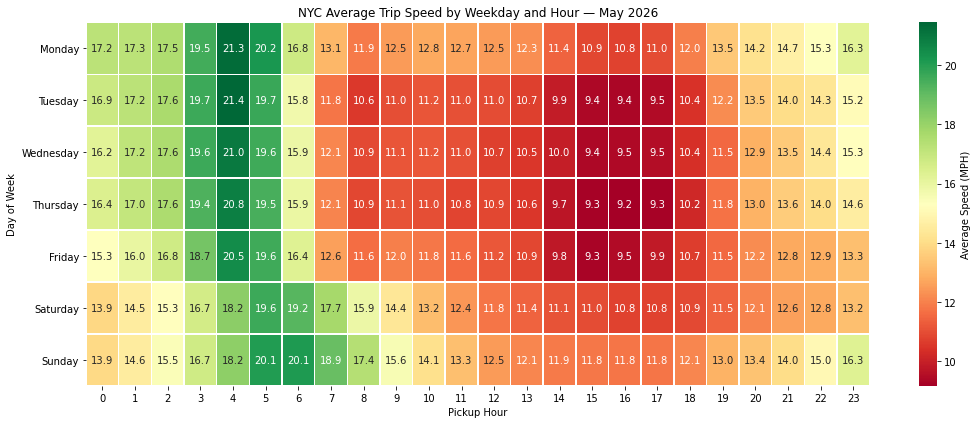

In [21]:
# Q1 - Step 6: Traffic Heatmap

# Combine Yellow Taxi and Uber/Lyft
traffic_data = pd.concat([
    yellow_q1[["Weekday", "Hour", "Average_Speed"]],
    uberlyft_q1[["Weekday", "Hour", "Average_Speed"]]
], ignore_index=True)

# Set weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Create pivot table
traffic_heatmap = traffic_data.pivot_table(
    index="Weekday",
    columns="Hour",
    values="Average_Speed",
    aggfunc="mean"
).reindex(weekday_order)

# Plot heatmap
plt.figure(figsize=(15, 6))

sns.heatmap(
    traffic_heatmap,
    cmap="RdYlGn",
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    cbar_kws={"label": "Average Speed (MPH)"}
)

plt.title("NYC Average Trip Speed by Weekday and Hour — May 2026")
plt.xlabel("Pickup Hour")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()

### Best Service by Day & Hour

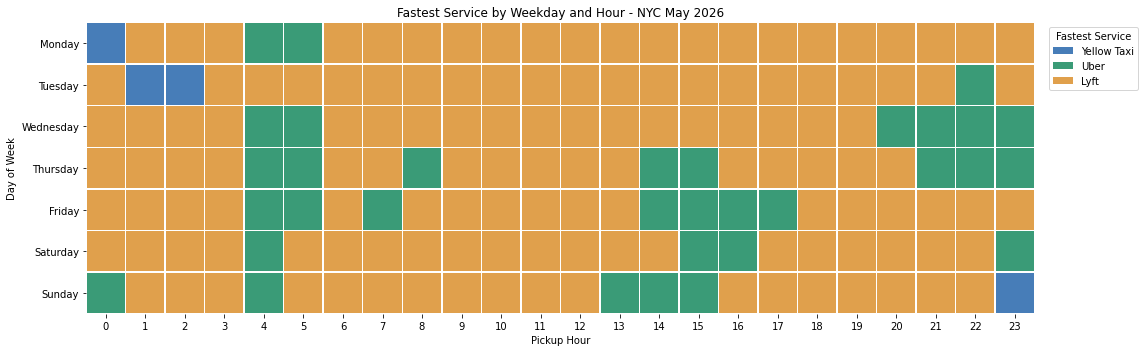

In [23]:
# Q1 - Step 7: Best Service by Day and Hour

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Average speed for each service, weekday and hour
service_speed = (
    traffic_data
    .groupby(["Weekday", "Hour", "Service"])["Average_Speed"]
    .mean()
    .reset_index()
)

# Convert services into columns
speed_comparison = service_speed.pivot_table(
    index=["Weekday", "Hour"],
    columns="Service",
    values="Average_Speed"
)

services = ["Yellow Taxi", "Uber", "Lyft"]
speed_comparison = speed_comparison.reindex(columns=services)

# Find fastest service for each weekday and hour
best_service = speed_comparison.idxmax(axis=1)

# Convert service names into numeric values
service_codes = {
    "Yellow Taxi": 0,
    "Uber": 1,
    "Lyft": 2
}

best_service_codes = (
    best_service.map(service_codes)
    .unstack("Hour")
    .reindex(
        index=["Monday", "Tuesday", "Wednesday",
               "Thursday", "Friday", "Saturday", "Sunday"],
        columns=range(24)
    )
)

# Set colors
colors = ["#477db8", "#3a9b77", "#e0a04c"]
cmap = ListedColormap(colors)

# Plot
plt.figure(figsize=(16, 5))

sns.heatmap(
    best_service_codes,
    cmap=cmap,
    vmin=-0.5,
    vmax=2.5,
    linewidths=0.5,
    cbar=False
)

plt.title("Fastest Service by Weekday and Hour - NYC May 2026")
plt.xlabel("Pickup Hour")
plt.ylabel("Day of Week")

legend = [
    Patch(facecolor=colors[i], label=services[i])
    for i in range(3)
]

plt.legend(
    handles=legend,
    title="Fastest Service",
    bbox_to_anchor=(1.01, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


In [24]:
# Count how many weekday-hour combinations each service wins

best_service_summary = (
    best_service.value_counts()
    .reindex(services, fill_value=0)
    .reset_index()
)

best_service_summary.columns = [
    "Service", "Hours Ranked Fastest"
]

best_service_summary["Percentage"] = (
    best_service_summary["Hours Ranked Fastest"]
    / len(best_service) * 100
).round(2)

display(best_service_summary)

,Service,Hours Ranked Fastest,Percentage
0,Yellow Taxi,4,2.38
1,Uber,33,19.64
2,Lyft,131,77.98


## Find out Busiest time -> Check Driver Efficiency -> Check customer waiting time -> Decide which time should adjust their dirver schedule

### Step 8: Afternoon Coverage Analysis

In [25]:
traffic_data = pd.concat([
    yellow_q1[["Service", "Weekday", "Hour", "Average_Speed"]],
    uberlyft_q1[["Service", "Weekday", "Hour", "Average_Speed"]]
], ignore_index=True)

traffic_data.head()

,Service,Weekday,Hour,Average_Speed
0,Yellow Taxi,Friday,0,16.198922
1,Yellow Taxi,Friday,0,16.229075
2,Yellow Taxi,Friday,0,7.218045
3,Yellow Taxi,Friday,0,9.473684
4,Yellow Taxi,Friday,0,13.950000


In [29]:
# Step 8.1: Afternoon Trip Patterns

# Combine cleaned datasets
service_data = pd.concat([
    yellow_q1[[
        "Service", "Hour", "Weekday",
        "Trip_Duration", "Average_Speed"
    ]],
    uberlyft_q1[[
        "Service", "Hour", "Weekday",
        "Trip_Duration", "Average_Speed"
    ]]
], ignore_index=True)

# Filter afternoon hours (12 PM - 6 PM)
service_data = service_data[
    service_data["Hour"].between(0, 23)
].copy()

# Calculate hourly metrics
service_summary = (
    service_data
    .groupby(["Service", "Hour"])
    .agg(
        Total_Trips=("Trip_Duration", "size"),
        Avg_Trip_Duration=("Trip_Duration", "mean"),
        Avg_Speed=("Average_Speed", "mean")
    )
    .reset_index()
)

# Find peak hour for each service
peak_hours = service_summary.loc[
    service_summary.groupby("Service")["Total_Trips"].idxmax()
].copy()

print("Peak Hour by Service")
display(peak_hours.round(2))

# Find overall peak hour across all services
overall_hourly = (
    service_summary
    .groupby("Hour")["Total_Trips"]
    .sum()
    .reset_index()
)

overall_peak = overall_hourly.loc[
    overall_hourly["Total_Trips"].idxmax()
]

print(f"Overall Peak Hour: {int(overall_peak['Hour']):02d}:00")
print(f"Total Trips: {int(overall_peak['Total_Trips']):,}")

Peak Hour by Service


,Service,Hour,Total_Trips,Avg_Trip_Duration,Avg_Speed
19,Lyft,19,396062,19.59,12.69
42,Uber,18,886989,20.69,11.27
66,Yellow Taxi,18,254241,17.74,8.97


Overall Peak Hour: 18:00
Total Trips: 1,532,570


### Peak Hour Analysis

* The highest trip volume occurs at 18:00, with 1.53 million completed trips.

* Uber and Yellow Taxi reach their peak at 18:00, while Lyft peaks at 19:00.

* High trip volumes between 17:00 and 19:00 suggest increased service activity during the evening rush hour.

* Driver coverage should be evaluated during these hours to reduce pickup wait times and improve operational efficiency.

### Visualization

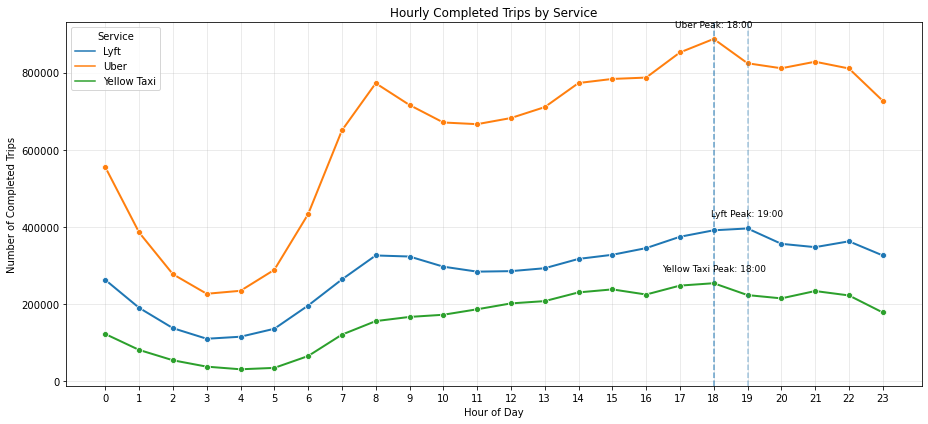

In [30]:
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=service_summary,
    x="Hour",
    y="Total_Trips",
    hue="Service",
    marker="o",
    linewidth=2
)

# Mark peak hour for each service
for _, row in peak_hours.iterrows():
    plt.axvline(
        x=row["Hour"],
        linestyle="--",
        alpha=0.4
    )

    plt.annotate(
        f"{row['Service']} Peak: {int(row['Hour']):02d}:00",
        xy=(row["Hour"], row["Total_Trips"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

plt.title("Hourly Completed Trips by Service")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Completed Trips")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Top 5 Busiest hour

In [31]:
# Top 5 busiest hours across all services
top5_hours = (
    overall_hourly
    .sort_values("Total_Trips", ascending=False)
    .head(5)
    .copy()
)

top5_hours["Time"] = (
    top5_hours["Hour"].astype(str).str.zfill(2) + ":00"
)

display(top5_hours[["Time", "Total_Trips"]])

,Time,Total_Trips
18,18:00,1532570
17,17:00,1474571
19,19:00,1443494
21,21:00,1409585
22,22:00,1395792


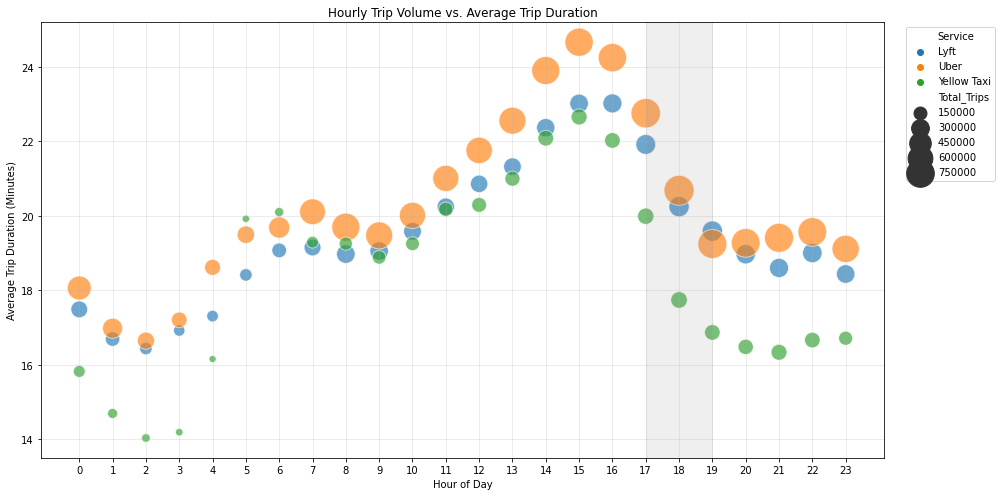

In [32]:
# Step 8.4: Trip Volume vs. Trip Duration

plt.figure(figsize=(14, 7))

sns.scatterplot(
    data=service_summary,
    x="Hour",
    y="Avg_Trip_Duration",
    hue="Service",
    size="Total_Trips",
    sizes=(50, 900),
    alpha=0.65
)

plt.axvspan(17, 19, color="gray", alpha=0.12)

plt.title("Hourly Trip Volume vs. Average Trip Duration")
plt.xlabel("Hour of Day")
plt.ylabel("Average Trip Duration (Minutes)")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### Highest Volume time is not the longest Trip Duration time
### Trip Volume vs. Average Trip Duration

* 14:00–16:00: Trip durations reach their highest levels, potentially reducing driver turnover.

* 17:00–19:00: Trip volumes peak, indicating increased service activity during the evening rush hour.

* Operational Implication: Driver allocation should consider both trip volume and trip duration rather than trip volume alone.

* Recommendation: Evaluate additional driver coverage before the evening peak to maintain service efficiency.

### Step 9: Calculate Pickup Wait Time

In [33]:
uberlyft_q1["request_datetime"] = pd.to_datetime(
    uberlyft_q1["request_datetime"]
)

uberlyft_q1["Pickup_Wait"] = (
    uberlyft_q1["pickup_datetime"] -
    uberlyft_q1["request_datetime"]
).dt.total_seconds() / 60

# Remove invalid waiting times
wait_data = uberlyft_q1[
    uberlyft_q1["Pickup_Wait"].between(0, 60)
].copy()

# Calculate average wait by service and hour
wait_summary = (
    wait_data
    .groupby(["Service", "Hour"])
    .agg(
        Avg_Wait=("Pickup_Wait", "mean"),
        Median_Wait=("Pickup_Wait", "median"),
        Total_Trips=("Pickup_Wait", "size")
    )
    .reset_index()
)

display(wait_summary.round(2))

,Service,Hour,Avg_Wait,Median_Wait,Total_Trips
0,Lyft,0,5.57,4.75,262005
1,Lyft,1,5.23,4.50,189993
2,Lyft,2,5.15,4.53,137204
3,Lyft,3,5.48,4.90,108126
4,Lyft,4,6.21,5.65,110644
5,Lyft,5,5.65,5.15,130797
6,Lyft,6,5.40,4.93,191565
7,Lyft,7,5.83,5.25,257839
8,Lyft,8,5.53,4.98,318413
9,Lyft,9,4.91,4.42,315386


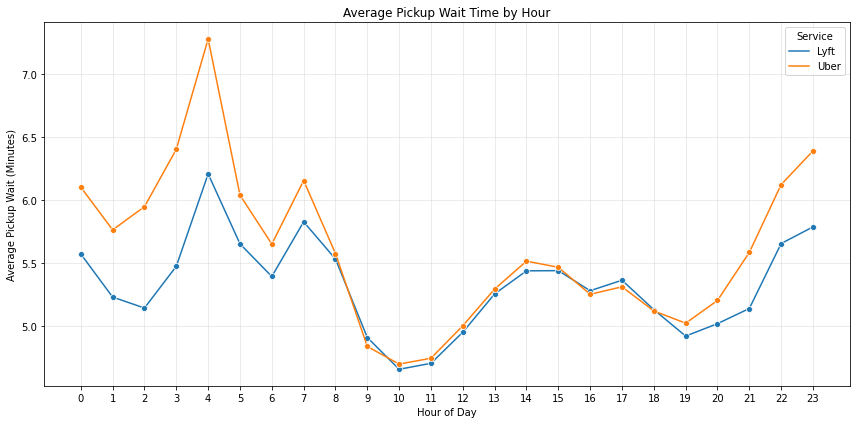

In [35]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=wait_summary,
    x="Hour",
    y="Avg_Wait",
    hue="Service",
    marker="o"
)

plt.title("Average Pickup Wait Time by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Pickup Wait (Minutes)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Pickup Wait Time Analysis

* 04:00: Uber records the longest pickup wait (~7.3 min), suggesting a potential early-morning coverage gap.

* 14:00–16:00: Despite longer trip durations, pickup waits remain relatively stable at 5.3–5.5 minutes.

* 18:00: The highest trip volume does not result in longer pickup waits (~5.1 min).

* Operational Implication: High trip volume alone does not indicate insufficient driver coverage. Driver allocation should consider actual pickup wait times.

### Step 10: Driver Productivity Proxy

In [40]:
productivity_summary = (
    service_data
    .groupby(["Service", "Hour"])
    .agg(
        Completed_Trips=("Trip_Duration", "size"),
        Total_Trip_Minutes=("Trip_Duration", "sum")
    )
    .reset_index()
)

# Trips per Occupied Hour = Completed Trips / Total Trip Duration(Hours)
# Shows the efficiency of driver

productivity_summary["Trips_per_Occupied_Hour"] = (
    productivity_summary["Completed_Trips"] /
    (productivity_summary["Total_Trip_Minutes"] / 60)
)

productivity_summary.round(2).head()

,Service,Hour,Completed_Trips,Total_Trip_Minutes,Trips_per_Occupied_Hour
0,Lyft,0,262840,4597191.13,3.43
1,Lyft,1,190493,3179979.42,3.59
2,Lyft,2,137838,2265867.00,3.65
3,Lyft,3,110415,1868373.33,3.55
4,Lyft,4,115678,2002389.12,3.47


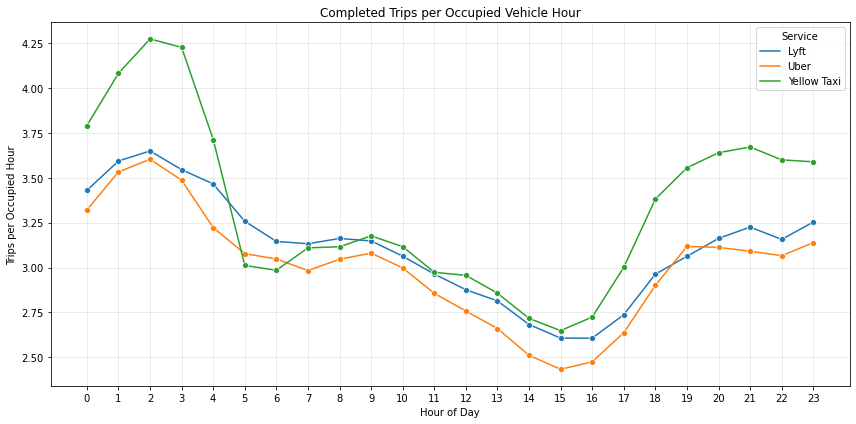

In [38]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=productivity_summary,
    x="Hour",
    y="Trips_per_Occupied_Hour",
    hue="Service",
    marker="o"
)

plt.title("Completed Trips per Occupied Vehicle Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Trips per Occupied Hour")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Occupied-Time Throughput Analysis

* 14:00–16:00: All three services experience their lowest occupied-time throughput due to longer average trip durations.

* Uber: Records the lowest throughput at approximately 2.43 trips per occupied hour at 15:00.

* After 17:00: Throughput improves as average trip durations decrease.

* Operational Implication: Afternoon driver coverage should account for longer trip durations, while evening coverage should consider higher trip volumes.

### Time Period	Recommendation
* 14:00–16:00	Longest trip duration and lowest occupied-time throughput	Maintain sufficient coverage to account for longer trips
* 17:00–19:00	Highest completed trip volume, but relatively stable pickup waits	Maintain peak-hour coverage and monitor waiting times
* 22:00–04:00	Pickup wait increases, especially for Uber	Investigate potential overnight driver coverage gaps

### Step 11: Operation Decision Heatmap
### Metric
* Pickup Wait, Weight: 50%, Reason: Direct customer service KPI
* Trip Volume, Weight: 30%, Reason: Service activity
* Trip Duration, Weight: 20%, Reason: Vehicle time commitment

In [42]:
# Combine trip metrics with pickup wait
decision_data = service_summary.merge(
    wait_summary[["Service", "Hour", "Avg_Wait"]],
    on=["Service", "Hour"],
    how="inner"
)

# Keep Uber and Lyft
decision_data = decision_data[
    decision_data["Service"].isin(["Uber", "Lyft"])
].copy()

# Normalize within each service
metrics = ["Total_Trips", "Avg_Trip_Duration", "Avg_Wait"]

for metric in metrics:
    min_val = decision_data.groupby("Service")[metric].transform("min")
    max_val = decision_data.groupby("Service")[metric].transform("max")

    decision_data[metric + "_Norm"] = (
        (decision_data[metric] - min_val) /
        (max_val - min_val).replace(0, np.nan)
    ).fillna(0)

# Calculate priority score
decision_data["Priority_Score"] = (
    0.50 * decision_data["Avg_Wait_Norm"] +
    0.30 * decision_data["Total_Trips_Norm"] +
    0.20 * decision_data["Avg_Trip_Duration_Norm"]
) * 100

display(decision_data.round(2))

,Service,Hour,Total_Trips,Avg_Trip_Duration,Avg_Speed,Avg_Wait,Total_Trips_Norm,Avg_Trip_Duration_Norm,Avg_Wait_Norm,Priority_Score
0,Lyft,0,262840,17.49,15.60,5.57,0.53,0.16,0.59,48.70
1,Lyft,1,190493,16.69,16.08,5.23,0.28,0.04,0.37,27.66
2,Lyft,2,137838,16.44,16.68,5.15,0.10,0.00,0.31,18.55
3,Lyft,3,110415,16.92,18.32,5.48,0.00,0.07,0.53,27.83
4,Lyft,4,115678,17.31,19.75,6.21,0.02,0.13,1.00,53.20
5,Lyft,5,136283,18.42,19.86,5.65,0.09,0.30,0.64,40.82
6,Lyft,6,196421,19.08,17.40,5.40,0.30,0.40,0.47,40.79
7,Lyft,7,264083,19.15,13.96,5.83,0.54,0.41,0.75,62.12
8,Lyft,8,326151,18.98,12.73,5.53,0.76,0.39,0.56,58.57
9,Lyft,9,323400,19.06,13.08,4.91,0.75,0.40,0.16,38.45


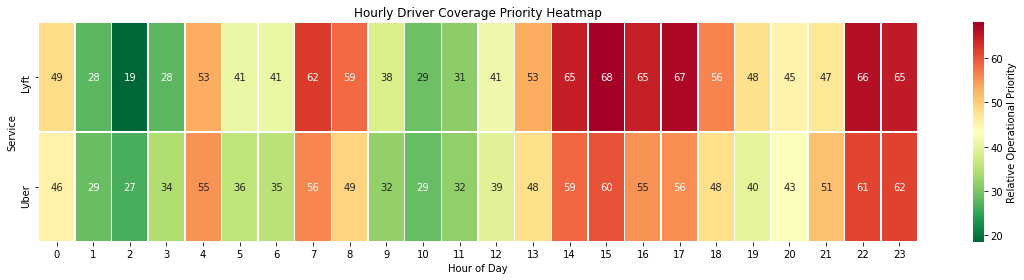

In [45]:
# Create Operation Decision heat map
heatmap_data = decision_data.pivot(
    index="Service",
    columns="Hour",
    values="Priority_Score"
)

plt.figure(figsize=(16, 4))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn_r",
    vmin=heatmap_data.min().min(),
    vmax=heatmap_data.max().max(),
    linewidths=0.5,
    cbar_kws={"label": "Relative Operational Priority"}
)

plt.title("Hourly Driver Coverage Priority Heatmap")
plt.xlabel("Hour of Day")
plt.ylabel("Service")
plt.tight_layout()
plt.show()

In [44]:
top_priority = (
    decision_data
    .sort_values("Priority_Score", ascending=False)
    .head(5)
)

display(
    top_priority[[
        "Service",
        "Hour",
        "Total_Trips",
        "Avg_Trip_Duration",
        "Avg_Wait",
        "Priority_Score"
    ]].round(2)
)

,Service,Hour,Total_Trips,Avg_Trip_Duration,Avg_Wait,Priority_Score
15,Lyft,15,327895,23.02,5.44,68.07
17,Lyft,17,374535,21.92,5.37,67.18
22,Lyft,22,362762,19.01,5.66,66.48
23,Lyft,23,326192,18.44,5.79,65.17
14,Lyft,14,317223,22.37,5.44,64.93


### Operational Recommendations

#### Prioritize Afternoon Driver Coverage (14:00–17:00)

* Longer trip durations and higher operational priority scores suggest that afternoon hours should receive additional attention in driver coverage planning.

#### Maintain Evening Peak Coverage (17:00–19:00)

* Although completed trip volume peaks at 18:00, pickup wait times remain relatively stable, suggesting that current coverage may be handling observed trip activity effectively.

#### Review Late-Night Driver Availability (22:00–23:00)

* Increasing pickup wait times during late-night hours indicate an opportunity to investigate driver availability and improve service responsiveness.

### Step 12: Use ML to forecast future service volume in different time

In [50]:
# Prepare Data for Machine Learning
# Combine cleaned datasets
ml_data = pd.concat([
    yellow_q1[["Date", "Hour", "Weekday", "Service"]],
    uberlyft_q1[["Date", "Hour", "Weekday", "Service"]]
], ignore_index=True)

# Convert Date to datetime
ml_data["Date"] = pd.to_datetime(ml_data["Date"])

# Count completed trips by date, hour and service
ml_hourly = (
    ml_data
    .groupby(["Date", "Hour", "Weekday", "Service"])
    .size()
    .reset_index(name="Total_Trips")
)

# Sort data
ml_hourly = ml_hourly.sort_values(
    ["Date", "Hour", "Service"]
).reset_index(drop=True)

print("Dataset Shape:", ml_hourly.shape)

display(ml_hourly.tail(10))

Dataset Shape: (2232, 5)


,Date,Hour,Weekday,Service,Total_Trips
2222,2026-05-31,20,Sunday,Yellow Taxi,5270
2223,2026-05-31,21,Sunday,Lyft,10106
2224,2026-05-31,21,Sunday,Uber,23496
2225,2026-05-31,21,Sunday,Yellow Taxi,5384
2226,2026-05-31,22,Sunday,Lyft,9763
2227,2026-05-31,22,Sunday,Uber,22565
2228,2026-05-31,22,Sunday,Yellow Taxi,4710
2229,2026-05-31,23,Sunday,Lyft,8614
2230,2026-05-31,23,Sunday,Uber,18733
2231,2026-05-31,23,Sunday,Yellow Taxi,3070


In [51]:
# Check data completeness

print("Number of Dates:", ml_hourly["Date"].nunique())
print("Number of Services:", ml_hourly["Service"].nunique())

print("\nMissing Values:")
print(ml_hourly.isnull().sum())

print("\nTrip Volume Summary:")
display(
    ml_hourly.groupby("Service")["Total_Trips"].describe().round(2)
)

Number of Dates: 31
Number of Services: 3

Missing Values:
Date           0
Hour           0
Weekday        0
Service        0
Total_Trips    0
dtype: int64

Trip Volume Summary:


,count,mean,std,min,25%,50%,75%,max
Service,,,,,,,,
Lyft,744.0,9097.74,3320.15,1499.0,7010.50,9748.0,11524.75,17116.0
Uber,744.0,20633.04,7981.44,3420.0,15066.00,22556.5,26076.50,40927.0
Yellow Taxi,744.0,5258.06,2731.98,214.0,2749.75,5937.0,7406.75,10800.0


In [52]:
# Train-Test Split

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Convert categorical features into dummy variables
ml_model = pd.get_dummies(
    ml_hourly,
    columns=["Weekday", "Service"],
    drop_first=False
)

# Define features
features = [
    col for col in ml_model.columns
    if col not in ["Date", "Total_Trips"]
]

X = ml_model[features]
y = ml_model["Total_Trips"]

# Time-based split
train_mask = ml_model["Date"] < "2026-05-25"
test_mask = ml_model["Date"] >= "2026-05-25"

X_train = X[train_mask]
X_test = X[test_mask]

y_train = y[train_mask]
y_test = y[test_mask]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nFeatures:")
print(features)

Training Data: (1728, 11)
Testing Data: (504, 11)

Features:
['Hour', 'Weekday_Friday', 'Weekday_Monday', 'Weekday_Saturday', 'Weekday_Sunday', 'Weekday_Thursday', 'Weekday_Tuesday', 'Weekday_Wednesday', 'Service_Lyft', 'Service_Uber', 'Service_Yellow Taxi']


In [53]:
# Train Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predict testing data
y_pred = rf_model.predict(X_test)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


In [54]:
# Model Evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Random Forest Model Performance")
print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²: {r2:.4f}")

Random Forest Model Performance
MAE: 1,175.81
RMSE: 1,930.33
R²: 0.9414


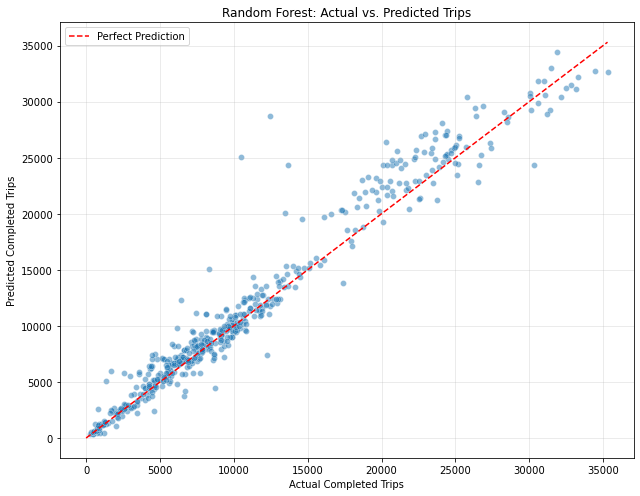

In [55]:
# Actual vs. Predicted

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.5
)

max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [0, max_val],
    [0, max_val],
    "r--",
    label="Perfect Prediction"
)

plt.title("Random Forest: Actual vs. Predicted Trips")
plt.xlabel("Actual Completed Trips")
plt.ylabel("Predicted Completed Trips")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [56]:
# Cross-Validation

from sklearn.model_selection import TimeSeriesSplit, cross_validate

# Sort training data chronologically
train_data = ml_model.loc[train_mask].sort_values(
    "Date"
).copy()

X_cv = train_data[features]
y_cv = train_data["Total_Trips"]

# Each day contains 72 observations (24 hours × 3 services)
tscv = TimeSeriesSplit(
    n_splits=4,
    test_size=72 * 4
)

cv_results = cross_validate(
    rf_model,
    X_cv,
    y_cv,
    cv=tscv,
    scoring="r2",
    return_train_score=True,
    n_jobs=-1
)

print(
    f"Mean training R²: "
    f"{cv_results['train_score'].mean():.4f}"
)

print(
    f"Mean validation R²: "
    f"{cv_results['test_score'].mean():.4f}"
)

print(
    f"Validation R² standard deviation: "
    f"{cv_results['test_score'].std():.4f}"
)

Mean training R²: 0.9769
Mean validation R²: 0.9471
Validation R² standard deviation: 0.0223


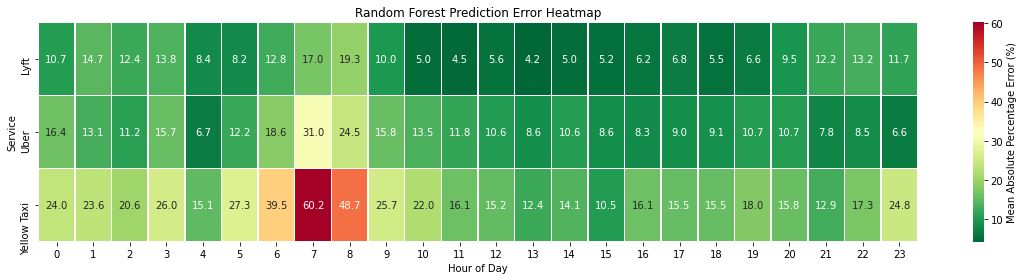

In [57]:
# Prediction Error Heatmap

# Create prediction results
results = ml_hourly.loc[test_mask, [
    "Date", "Hour", "Service"
]].copy()

results["Actual"] = y_test.to_numpy()
results["Predicted"] = y_pred

# Calculate Absolute Percentage Error
results["APE"] = (
    abs(results["Actual"] - results["Predicted"]) /
    results["Actual"].replace(0, np.nan)
) * 100

# Average error by service and hour
error_heatmap = results.pivot_table(
    index="Service",
    columns="Hour",
    values="APE",
    aggfunc="mean"
)

plt.figure(figsize=(16, 4))

sns.heatmap(
    error_heatmap,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    linewidths=0.5,
    cbar_kws={"label": "Mean Absolute Percentage Error (%)"}
)

plt.title("Random Forest Prediction Error Heatmap")
plt.xlabel("Hour of Day")
plt.ylabel("Service")
plt.tight_layout()
plt.show()

### Forecast June service Volume using ML

In [58]:
# Retrain Random Forest with Full May Data

from sklearn.ensemble import RandomForestRegressor

rf_final = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Train with all May observations
rf_final.fit(X, y)

print("Final Random Forest Model Trained!")
print("Training Observations:", len(X))

Final Random Forest Model Trained!
Training Observations: 2232


In [59]:
# Create June 2026 Dataset

import pandas as pd
import numpy as np

# June dates
june_dates = pd.date_range(
    start="2026-06-01",
    end="2026-06-30",
    freq="D"
)

# Create all combinations
june_data = pd.MultiIndex.from_product(
    [
        june_dates,
        range(24),
        ["Uber", "Lyft", "Yellow Taxi"]
    ],
    names=["Date", "Hour", "Service"]
).to_frame(index=False)

# Add weekday
june_data["Weekday"] = june_data["Date"].dt.day_name()

print("June Dataset Shape:", june_data.shape)

display(june_data.head(10))

June Dataset Shape: (2160, 4)


,Date,Hour,Service,Weekday
0,2026-06-01,0,Uber,Monday
1,2026-06-01,0,Lyft,Monday
2,2026-06-01,0,Yellow Taxi,Monday
3,2026-06-01,1,Uber,Monday
4,2026-06-01,1,Lyft,Monday
5,2026-06-01,1,Yellow Taxi,Monday
6,2026-06-01,2,Uber,Monday
7,2026-06-01,2,Lyft,Monday
8,2026-06-01,2,Yellow Taxi,Monday
9,2026-06-01,3,Uber,Monday


In [60]:
# Predict June Trip Volume

# Encode categorical variables
june_encoded = pd.get_dummies(
    june_data,
    columns=["Weekday", "Service"],
    drop_first=False
)

# Match training features
X_june = june_encoded.reindex(
    columns=features,
    fill_value=0
)

# Predict
june_data["Predicted_Trips"] = rf_final.predict(X_june)

# Round predictions to whole trips
june_data["Predicted_Trips"] = (
    june_data["Predicted_Trips"]
    .round()
    .clip(lower=0)
    .astype(int)
)

display(june_data.head(10))

,Date,Hour,Service,Weekday,Predicted_Trips
0,2026-06-01,0,Uber,Monday,13647
1,2026-06-01,0,Lyft,Monday,6965
2,2026-06-01,0,Yellow Taxi,Monday,2205
3,2026-06-01,1,Uber,Monday,7839
4,2026-06-01,1,Lyft,Monday,4285
5,2026-06-01,1,Yellow Taxi,Monday,1116
6,2026-06-01,2,Uber,Monday,5325
7,2026-06-01,2,Lyft,Monday,2688
8,2026-06-01,2,Yellow Taxi,Monday,609
9,2026-06-01,3,Uber,Monday,4667


In [61]:
# June Peak Hour Analysis

june_hourly = (
    june_data
    .groupby(["Service", "Hour"])["Predicted_Trips"]
    .mean() # Using mean() since we like to know the average
    .reset_index()
)

# Find peak hour for each service
june_peak = june_hourly.loc[
    june_hourly.groupby("Service")["Predicted_Trips"].idxmax()
]

print("Predicted June Peak Hours by Service")

display(june_peak.round(0))

Predicted June Peak Hours by Service


,Service,Hour,Predicted_Trips
19,Lyft,19,12473.0
42,Uber,18,27984.0
66,Yellow Taxi,18,8026.0


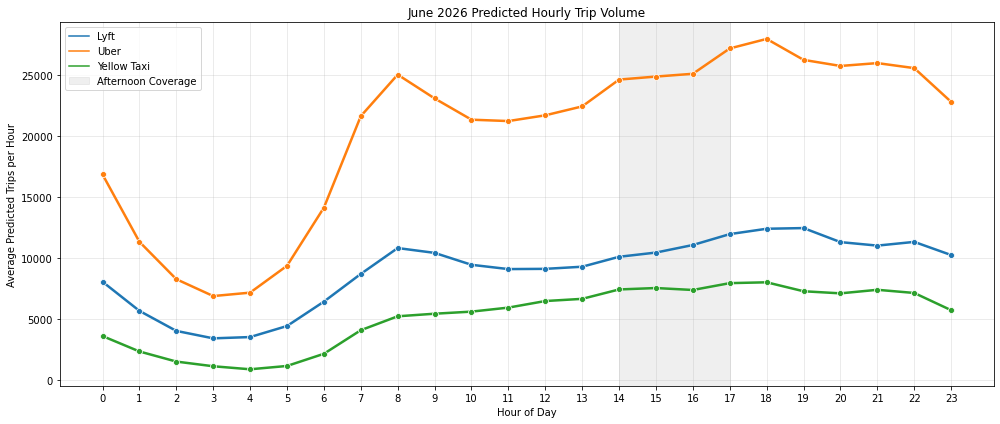

In [62]:
# June Predicted Hourly Trip Volume

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=june_hourly,
    x="Hour",
    y="Predicted_Trips",
    hue="Service",
    marker="o",
    linewidth=2.5,
    palette={
        "Lyft": "tab:blue",
        "Uber": "tab:orange",
        "Yellow Taxi": "tab:green"
    }
)

plt.axvspan(14, 17, color="gray", alpha=0.12,
            label="Afternoon Coverage")

plt.title("June 2026 Predicted Hourly Trip Volume")
plt.xlabel("Hour of Day")
plt.ylabel("Average Predicted Trips per Hour")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### June Forecast the busiest time is still from 14-17

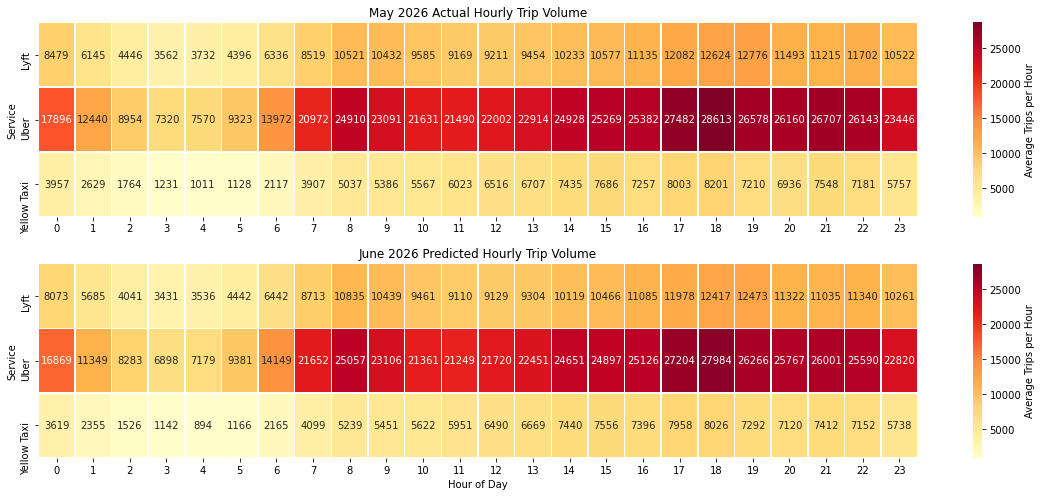

In [64]:
# May Actual vs. June Predicted Heatmaps

# May actual average hourly trips
may_hourly = (
    ml_hourly
    .groupby(["Service", "Hour"])["Total_Trips"]
    .mean()
    .reset_index()
)

may_heatmap = may_hourly.pivot(
    index="Service",
    columns="Hour",
    values="Total_Trips"
)

june_heatmap = june_hourly.pivot(
    index="Service",
    columns="Hour",
    values="Predicted_Trips"
)

# Same color scale for fair comparison
vmin = min(may_heatmap.min().min(),
           june_heatmap.min().min())

vmax = max(may_heatmap.max().max(),
           june_heatmap.max().max())

fig, axes = plt.subplots(2, 1, figsize=(16, 7))

sns.heatmap(
    may_heatmap,
    ax=axes[0],
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax,
    annot=True,
    fmt=".0f",
    linewidths=0.5,
    cbar_kws={"label": "Average Trips per Hour"}
)

axes[0].set_title("May 2026 Actual Hourly Trip Volume")
axes[0].set_xlabel("")
axes[0].set_ylabel("Service")

sns.heatmap(
    june_heatmap,
    ax=axes[1],
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax,
    annot=True,
    fmt=".0f",
    linewidths=0.5,
    cbar_kws={"label": "Average Trips per Hour"}
)

axes[1].set_title("June 2026 Predicted Hourly Trip Volume")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Service")

plt.tight_layout()
plt.show()

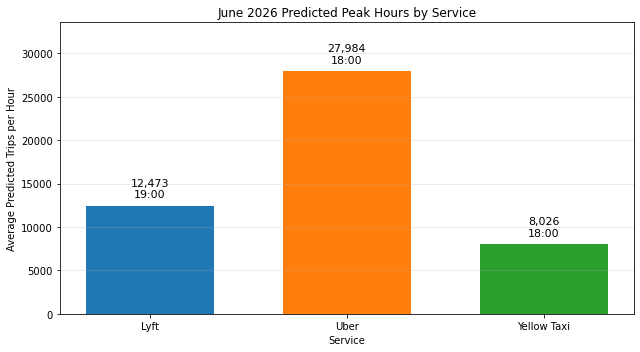

In [67]:
# Predicted Peak Hour by Service

# Sort services
june_peak_plot = june_peak.set_index("Service").loc[
    ["Lyft", "Uber", "Yellow Taxi"]
].reset_index()

colors = ["tab:blue", "tab:orange", "tab:green"]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    june_peak_plot["Service"],
    june_peak_plot["Predicted_Trips"],
    color=colors,
    width=0.65
)

# Add labels for all three services
for bar, (_, row) in zip(bars, june_peak_plot.iterrows()):

    height = bar.get_height()

    ax.annotate(
        f"{height:,.0f}\n{int(row['Hour']):02d}:00",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title("June 2026 Predicted Peak Hours by Service")
ax.set_xlabel("Service")
ax.set_ylabel("Average Predicted Trips per Hour")

ax.set_ylim(0, june_peak_plot["Predicted_Trips"].max() * 1.2)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### June 2026 Trip Volume Forecast

* Uber: Predicted peak activity occurs at 18:00, averaging approximately 27,984 completed trips.

* Lyft: Peak activity is expected at 19:00, averaging approximately 12,473 trips.

* Yellow Taxi: Predicted peak activity occurs at 18:00, averaging approximately 8,026 trips.

* Operational Implication: Maintain sufficient evening driver coverage while monitoring afternoon trip durations and pickup wait times.

* Recommendation: Use predicted hourly trip volumes to support driver coverage planning, particularly during the afternoon-to-evening transition.